# 📊 Section D: Plotting & Visualization Exercises

**AI-Generated Notebook** — This notebook was created by an AI (Junie) as a scaffold for your learning.
**Your job:** Run each cell, change parameters, and observe what happens. The goal is to internalize what synchronization **looks like**.

---

> **Prerequisites:** Complete Section C (Bézout's Identity) in `PRACTICE_PROBLEMS.md` before starting here.

---

In [2]:
"""
Setup: imports and style configuration.
"""
from __future__ import annotations

import matplotlib.pyplot as plt
import numpy as np

from kuramoto.analysis.viz import (
    set_style,
    plot_time_series,
    plot_network,
    plot_fluid_vorticity,
    PROJECT_COLORS,
    THEME_BG,
    TEXT_PRIMARY,
)
from kuramoto.api import generate_kuramoto_dataset
from kuramoto.order_parameter import compute_order_parameter
from kuramoto.topologies import load_topology

# Apply the dark theme
set_style()

print("✅ Setup complete. Ready for plotting exercises.")

✅ Setup complete. Ready for plotting exercises.


---

## Problem 19: Phase Portrait — Incoherent vs Synchronized

**Goal:** Visualize the difference between incoherent and synchronized states.

**Tasks:**
1. Run a Kuramoto simulation with `N=50` oscillators, `K=0.1` (weak coupling), and `T=10` seconds.
2. Run the same simulation with `K=3.0` (strong coupling).
3. Plot the phases `θᵢ(t)` as a function of time (a "phase portrait" or "spaghetti plot").
4. **Question:** What visual features distinguish the synchronized state from the incoherent state?

In [3]:
"""
Problem 19: Phase Portrait — Incoherent vs Synchronized
"""

# --- PARAMETERS ---
N = 50  # Number of oscillators
T = 10  # Simulation time in seconds
dt = 0.02  # Time step
timesteps = int(T / dt)
seed = 27  # Fixed seed for reproducibility

# Generate natural frequencies (uniform distribution)
omega = np.random.default_rng(seed).uniform(-1, 1, N)

# TODO: Fill in the coupling strengths
K_weak = 0.5  # Weak coupling (incoherent state)
K_strong = 2.0 # Strong coupling (synchronized state)

# --- RUN SIMULATIONS ---
# TODO: Run two simulations, one with weak coupling and one with strong coupling
dataset_weak = generate_kuramoto_dataset(
    n_oscillators=N,
    natural_frequencies=omega,
    coupling=K_weak,
    timesteps=timesteps,
    dt=dt,
    seed=seed,
)

dataset_strong = generate_kuramoto_dataset(
    n_oscillators=N,
    natural_frequencies=omega,
    coupling=K_strong,
    timesteps=timesteps,
    dt=dt,
    seed=seed,
)

print(f"Weak coupling (K={K_weak}): theta shape = {dataset_weak['theta'].shape}")
print(f"Strong coupling (K={K_strong}): theta shape = {dataset_strong['theta'].shape}")

Weak coupling (K=0.5): theta shape = (500, 50)
Strong coupling (K=2.0): theta shape = (500, 50)


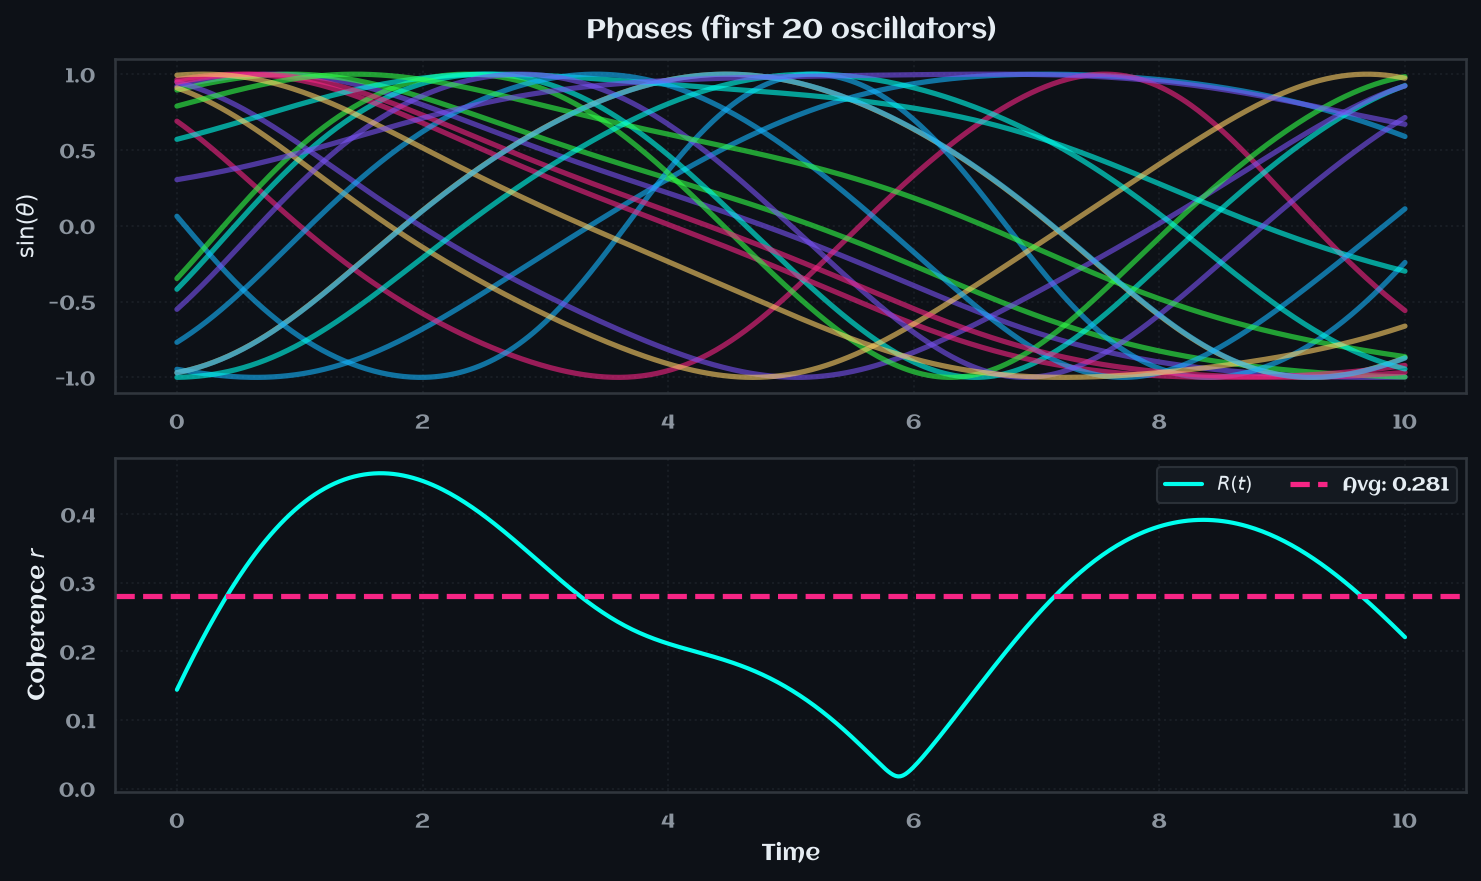

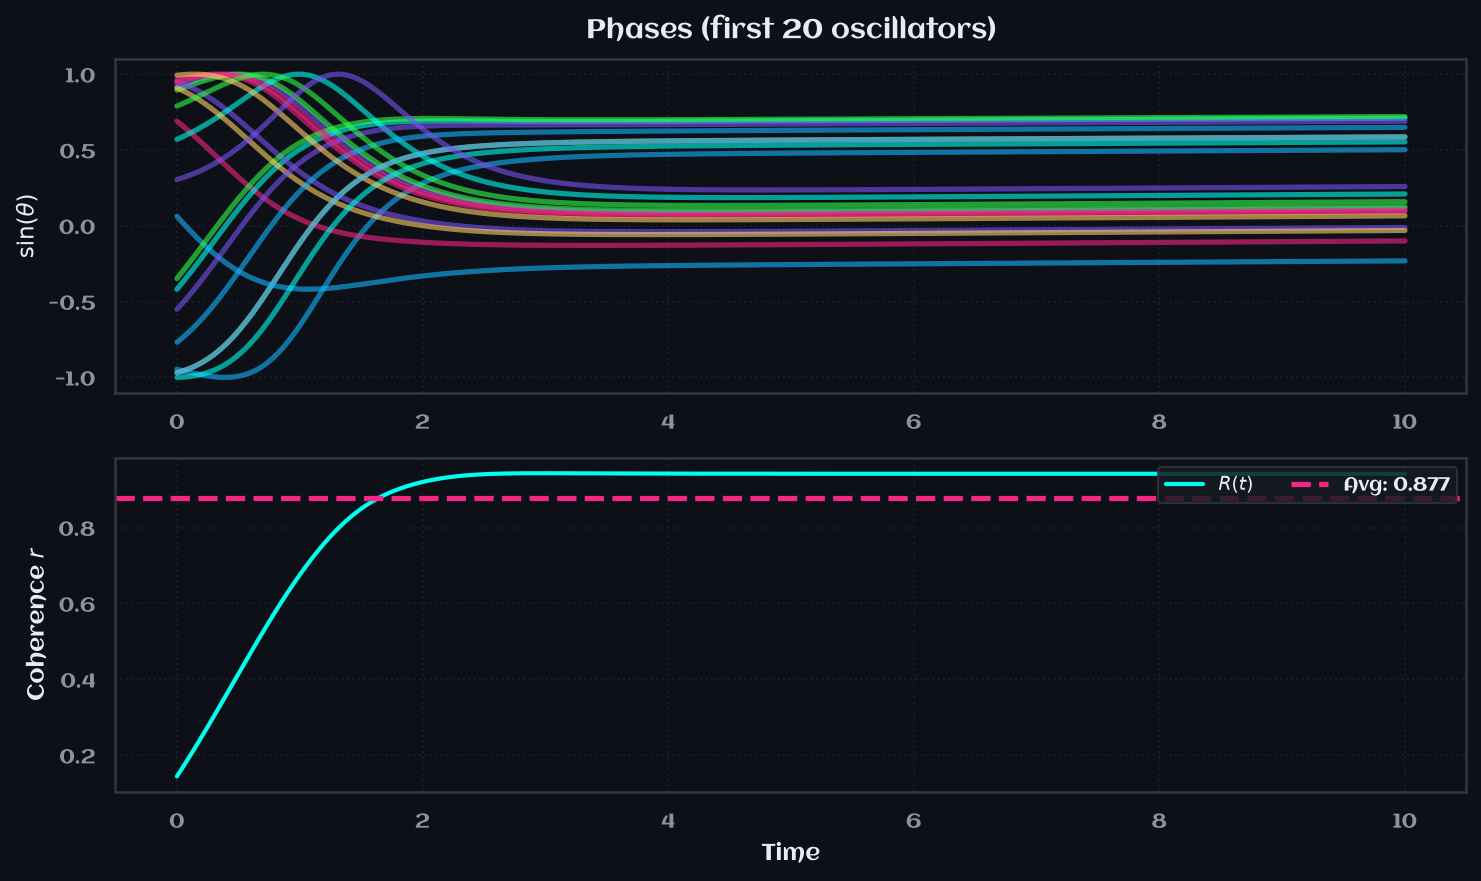


📝 Observation questions:
1. In the weak coupling plot, do the phase lines cross each other?
2. In the strong coupling plot, do the phase lines become parallel?
3. How does R(t) differ between the two cases?


In [4]:
"""
Problem 19: Plot the phase portraits side by side.
"""

# TODO: Use plot_time_series to create the phase portraits
# Hint: Call plot_time_series twice, once for each dataset

times = dataset_weak["time"]
r_weak = compute_order_parameter(dataset_weak["theta"])
r_strong = compute_order_parameter(dataset_strong["theta"])

# Plot weak coupling
plot_time_series(
    times=times,
    theta=dataset_weak["theta"],
    r_values=r_weak,
    n_oscillators=20,  # Plot first 20 oscillators for clarity
    title=f"Phase Portrait (K={K_weak} — Incoherent)",
)

# Plot strong coupling
plot_time_series(
    times=times,
    theta=dataset_strong["theta"],
    r_values=r_strong,
    n_oscillators=20,
    title=f"Phase Portrait (K={K_strong} — Synchronized)",
)

print("\n📝 Observation questions:")
print("1. In the weak coupling plot, do the phase lines cross each other?")
print("2. In the strong coupling plot, do the phase lines become parallel?")
print("3. How does R(t) differ between the two cases?")

---

## Problem 20: Order Parameter Dynamics

**Goal:** Track how synchronization emerges over time.

**Tasks:**
1. Run a simulation with `N=100` oscillators, natural frequencies drawn uniformly from `[-1, 1]`, coupling `K=2.0`, and `T=20` seconds.
2. Compute the order parameter `R(t)` at each timestep.
3. Plot `R(t)` and observe whether it approaches a steady state.
4. **Question:** What is the final synchronization strength? How does it change if you increase `K` to `4.0`?

In [5]:
"""
Problem 20: Order Parameter Dynamics
"""

# --- PARAMETERS ---
N = 100
T = 20
dt = 0.02
timesteps = int(T / dt)
seed = 42

# Generate natural frequencies
omega = np.random.default_rng(seed).uniform(-1, 1, N)

# TODO: Run simulations for two different coupling strengths
K1 = 2.0
K2 = 4.0

dataset_K1 = generate_kuramoto_dataset(
    n_oscillators=N,
    natural_frequencies=omega,
    coupling=K1,
    timesteps=timesteps,
    dt=dt,
    seed=seed,
)

dataset_K2 = generate_kuramoto_dataset(
    n_oscillators=N,
    natural_frequencies=omega,
    coupling=K2,
    timesteps=timesteps,
    dt=dt,
    seed=seed,
)

# Compute order parameters
r_K1 = compute_order_parameter(dataset_K1["theta"])
r_K2 = compute_order_parameter(dataset_K2["theta"])
times = dataset_K1["time"]

print(f"K={K1}: Final R = {r_K1[-1]:.4f}, Mean R (last 50%) = {np.mean(r_K1[len(r_K1)//2:]):.4f}")
print(f"K={K2}: Final R = {r_K2[-1]:.4f}, Mean R (last 50%) = {np.mean(r_K2[len(r_K2)//2:]):.4f}")

K=2.0: Final R = 0.9580, Mean R (last 50%) = 0.9580
K=4.0: Final R = 0.9905, Mean R (last 50%) = 0.9905


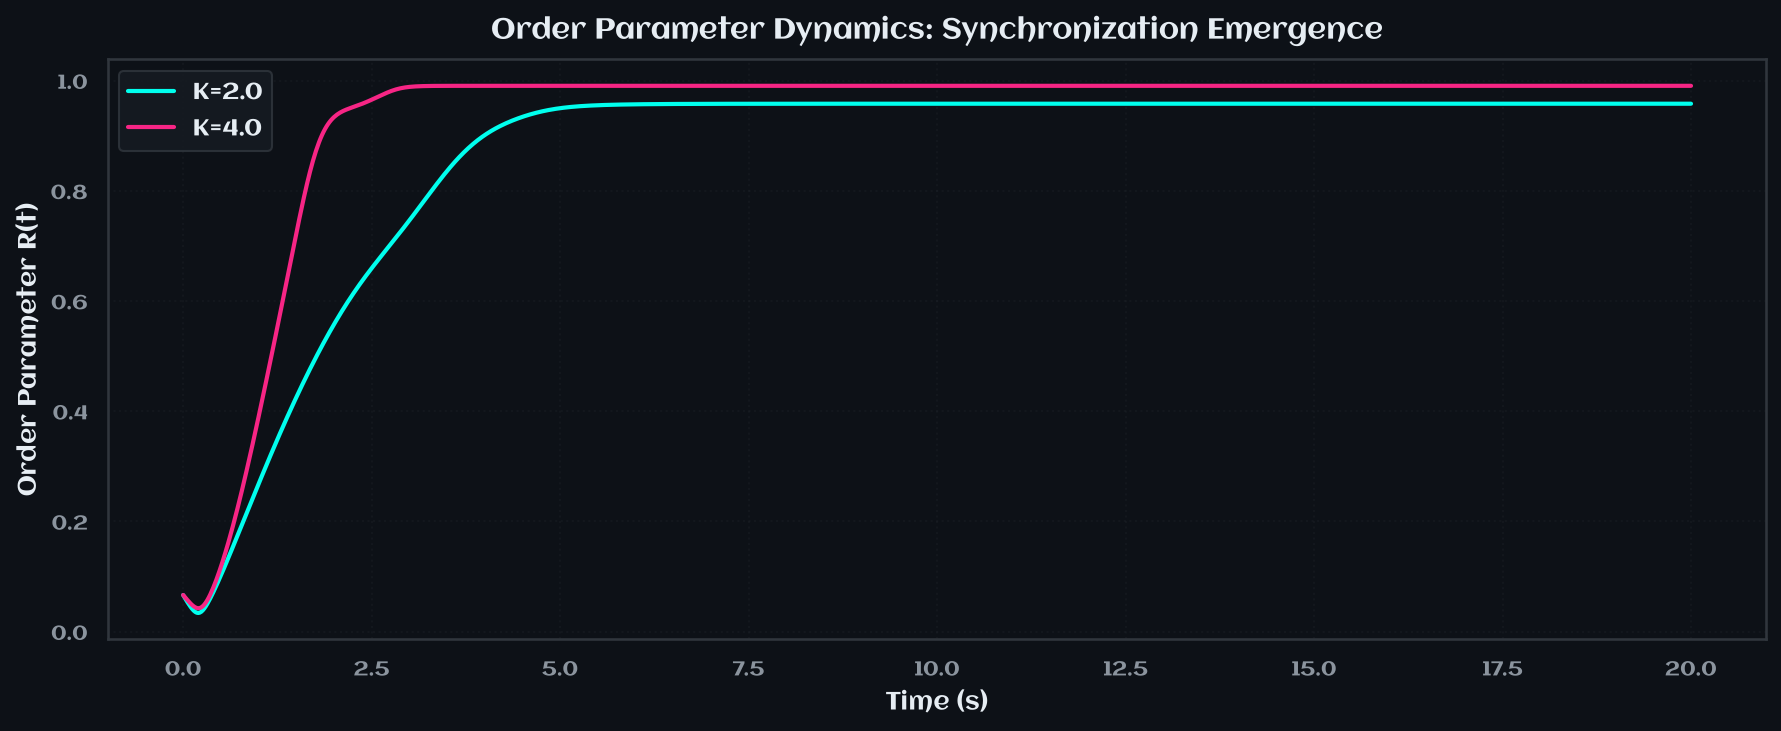


📝 Observation questions:
1. For K=2.0, does R(t) approach a steady state? If so, what value?
2. For K=4.0, is the final R higher or lower?
3. How long does it take for R(t) to stabilize?


In [6]:
"""
Problem 20: Plot R(t) for both coupling strengths on the same graph.
"""

# TODO: Create a single plot showing both R(t) curves
set_style()
fig, ax = plt.subplots(figsize=(12, 5), facecolor=THEME_BG)
ax.set_facecolor(THEME_BG)

# Plot R(t) for K=2.0
ax.plot(times, r_K1, label=f"K={K1}", linewidth=2, color=PROJECT_COLORS["cyan_light"])

# Plot R(t) for K=4.0
ax.plot(times, r_K2, label=f"K={K2}", linewidth=2, color=PROJECT_COLORS["pink_pink"])

# Add labels and legend
ax.set_xlabel("Time (s)", fontsize=12, color=TEXT_PRIMARY)
ax.set_ylabel("Order Parameter R(t)", fontsize=12, color=TEXT_PRIMARY)
ax.set_title("Order Parameter Dynamics: Synchronization Emergence", fontsize=14, fontweight="bold", color=TEXT_PRIMARY)
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("\n📝 Observation questions:")
print(f"1. For K={K1}, does R(t) approach a steady state? If so, what value?")
print(f"2. For K={K2}, is the final R higher or lower?")
print("3. How long does it take for R(t) to stabilize?")

---

## Problem 21: Natural Frequency Distribution

**Goal:** Visualize how frequency spread affects synchronization.

**Tasks:**
1. Generate two sets of natural frequencies:
   - **Set A:** Uniform distribution on `[-0.5, 0.5]` (narrow spread)
   - **Set B:** Uniform distribution on `[-2.0, 2.0]` (wide spread)
2. Run simulations with the same coupling `K=1.5` for both sets.
3. Plot the frequency distributions and compare `R(t)` for both cases.
4. **Question:** Which distribution achieves higher synchronization? Why?

In [7]:
"""
Problem 21: Natural Frequency Distribution
"""

# --- PARAMETERS ---
N = 100
T = 20
dt = 0.02
timesteps = int(T / dt)
K = 1.5
seed = 42
rng = np.random.default_rng(seed)

# TODO: Generate two frequency distributions
omega_narrow = rng.uniform(-0.5, 0.5, N)  # Narrow spread
omega_wide = rng.uniform(-2.0, 2.0, N)  # Wide spread

# Run simulations
dataset_narrow = generate_kuramoto_dataset(
    n_oscillators=N,
    natural_frequencies=omega_narrow,
    coupling=K,
    timesteps=timesteps,
    dt=dt,
    seed=seed,
)

dataset_wide = generate_kuramoto_dataset(
    n_oscillators=N,
    natural_frequencies=omega_wide,
    coupling=K,
    timesteps=timesteps,
    dt=dt,
    seed=seed,
)

r_narrow = compute_order_parameter(dataset_narrow["theta"])
r_wide = compute_order_parameter(dataset_wide["theta"])
times = dataset_narrow["time"]

print(f"Narrow spread: Final R = {r_narrow[-1]:.4f}")
print(f"Wide spread: Final R = {r_wide[-1]:.4f}")

Narrow spread: Final R = 0.9827
Wide spread: Final R = 0.1468


C:\Users\sofia\AppData\Local\Temp\ipykernel_47624\460556517.py:30: UserWarning: Glyph 969 (\N{GREEK SMALL LETTER OMEGA}) missing from font(s) Aclonica.
  plt.tight_layout()
C:\Users\sofia\PycharmProjects\kuramoto-benchmark-suite\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 969 (\N{GREEK SMALL LETTER OMEGA}) missing from font(s) Aclonica.
  fig.canvas.print_figure(bytes_io, **kw)


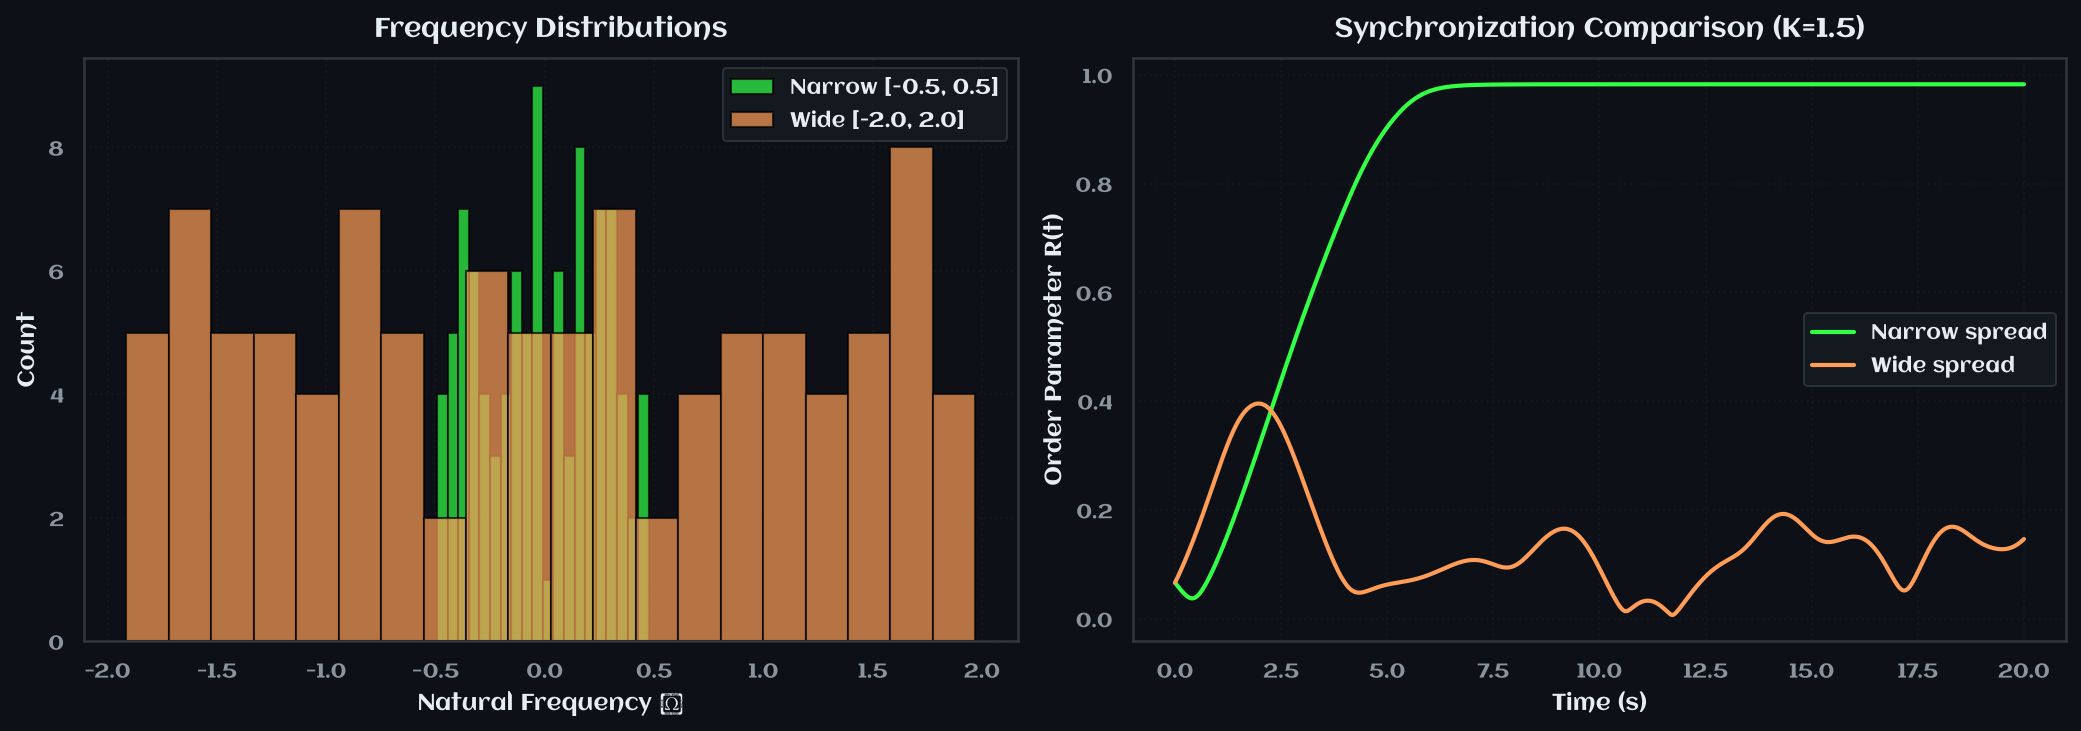


📝 Observation questions:
1. Which distribution achieves higher R(t)?
2. Why does a narrower frequency spread lead to easier synchronization?
3. Try changing K to 3.0 and re-running — does the wide spread catch up?


In [8]:
"""
Problem 21: Plot frequency distributions and R(t) comparison.
"""

set_style()
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), facecolor=THEME_BG)

# Left: Frequency distributions
ax1.hist(omega_narrow, bins=20, alpha=0.7, label="Narrow [-0.5, 0.5]", 
         color=PROJECT_COLORS["green_neon"], edgecolor='black')
ax1.hist(omega_wide, bins=20, alpha=0.7, label="Wide [-2.0, 2.0]", 
         color=PROJECT_COLORS["orange_warm"], edgecolor='black')
ax1.set_xlabel("Natural Frequency ω", fontsize=11, color=TEXT_PRIMARY)
ax1.set_ylabel("Count", fontsize=11, color=TEXT_PRIMARY)
ax1.set_title("Frequency Distributions", fontsize=13, fontweight="bold", color=TEXT_PRIMARY)
ax1.legend(fontsize=10)
ax1.grid(True, alpha=0.3)

# Right: R(t) comparison
ax2.plot(times, r_narrow, label="Narrow spread", linewidth=2, 
         color=PROJECT_COLORS["green_neon"])
ax2.plot(times, r_wide, label="Wide spread", linewidth=2, 
         color=PROJECT_COLORS["orange_warm"])
ax2.set_xlabel("Time (s)", fontsize=11, color=TEXT_PRIMARY)
ax2.set_ylabel("Order Parameter R(t)", fontsize=11, color=TEXT_PRIMARY)
ax2.set_title(f"Synchronization Comparison (K={K})", fontsize=13, fontweight="bold", color=TEXT_PRIMARY)
ax2.legend(fontsize=10)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("\n📝 Observation questions:")
print("1. Which distribution achieves higher R(t)?")
print("2. Why does a narrower frequency spread lead to easier synchronization?")
print("3. Try changing K to 3.0 and re-running — does the wide spread catch up?")

---

## Problem 22: Network Topology Visualization

**Goal:** See how network structure affects coupling.

**Tasks:**
1. Generate a **ring topology** with `N=20` nodes and a **small-world topology** with `N=20` nodes.
2. Visualize both topologies.
3. Run Kuramoto simulations on both topologies with the same coupling strength.
4. **Question:** Which topology synchronizes faster? Does the network structure matter for the final synchronization strength?

In [9]:
"""
Problem 22: Network Topology Visualization
"""

# --- PARAMETERS ---
N = 20
T = 20
dt = 0.02
timesteps = int(T / dt)
K = 2.0
seed = 42

# Generate natural frequencies
omega = np.random.default_rng(seed).uniform(-1, 1, N)

# TODO: Load two different topologies
adj_ring = load_topology("ring", n=N)
adj_small_world = load_topology("small_world", n=N, k=4, p=0.1)

print(f"Ring adjacency shape: {adj_ring.shape}")
print(f"Small-world adjacency shape: {adj_small_world.shape}")

Ring adjacency shape: (20, 20)
Small-world adjacency shape: (20, 20)


TypeError: plot_network() got an unexpected keyword argument 'ax'

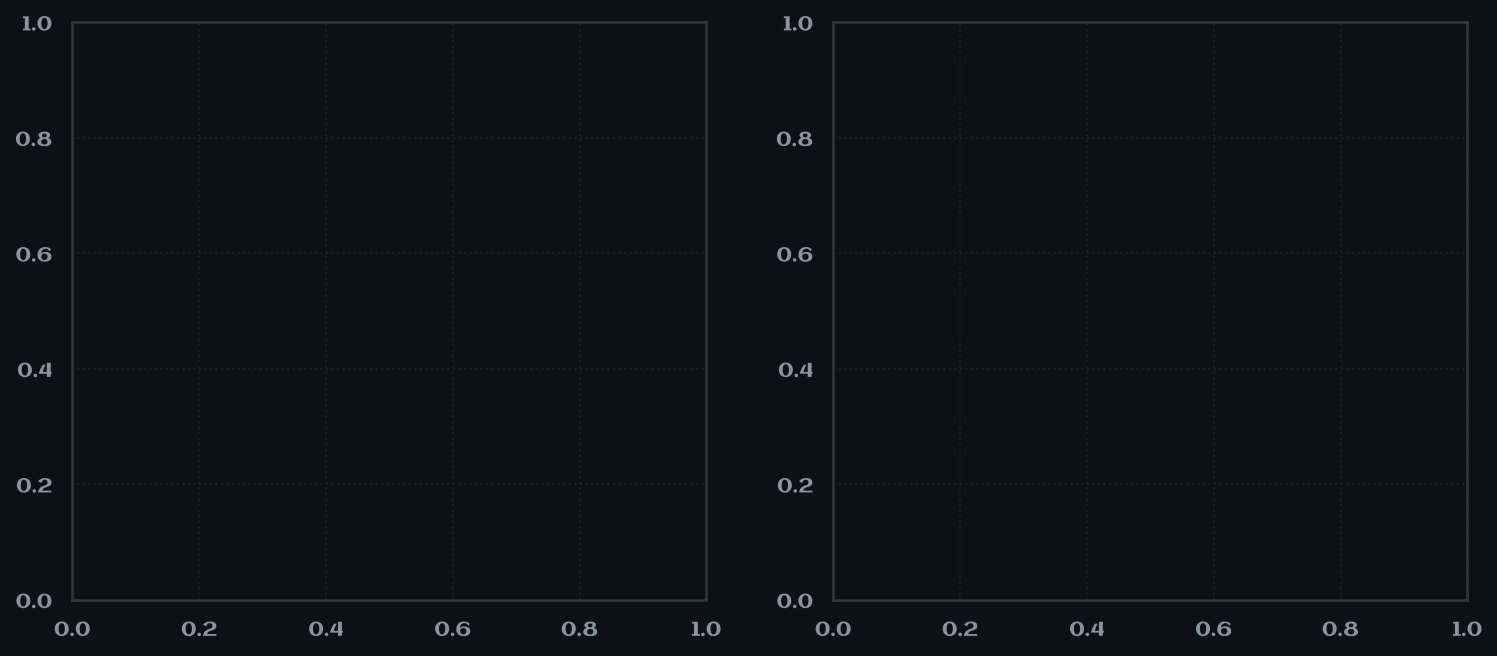

In [10]:
"""
Problem 22: Visualize the two network topologies.
"""

set_style()
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5), facecolor=THEME_BG)

# Plot ring topology
plot_network(adj_ring, title="Ring Topology", ax=ax1)

# Plot small-world topology
plot_network(adj_small_world, title="Small-World Topology", ax=ax2)

plt.tight_layout()
plt.show()

print("\n📝 Observation:")
print("The small-world network has 'shortcut' edges that bypass the ring structure.")
print("These shortcuts reduce the average path length between nodes.")

In [ ]:
"""
Problem 22: Run simulations on both topologies and compare R(t).
"""

# TODO: Run simulations on both topologies
dataset_ring = generate_kuramoto_dataset(
    n_oscillators=N,
    natural_frequencies=omega,
    coupling=K,
    timesteps=timesteps,
    dt=dt,
    adjacency=adj_ring,
    seed=seed,
)

dataset_small_world = generate_kuramoto_dataset(
    n_oscillators=N,
    natural_frequencies=omega,
    coupling=K,
    timesteps=timesteps,
    dt=dt,
    adjacency=adj_small_world,
    seed=seed,
)

r_ring = compute_order_parameter(dataset_ring["theta"])
r_small_world = compute_order_parameter(dataset_small_world["theta"])
times = dataset_ring["time"]

# Plot comparison
set_style()
fig, ax = plt.subplots(figsize=(12, 5), facecolor=THEME_BG)
ax.set_facecolor(THEME_BG)

ax.plot(times, r_ring, label="Ring Topology", linewidth=2, 
        color=PROJECT_COLORS["cyan_light"])
ax.plot(times, r_small_world, label="Small-World Topology", linewidth=2, 
        color=PROJECT_COLORS["purple_light"])

ax.set_xlabel("Time (s)", fontsize=12, color=TEXT_PRIMARY)
ax.set_ylabel("Order Parameter R(t)", fontsize=12, color=TEXT_PRIMARY)
ax.set_title(f"Topology Comparison (K={K})", fontsize=14, fontweight="bold", color=TEXT_PRIMARY)
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"\nRing final R: {r_ring[-1]:.4f}")
print(f"Small-world final R: {r_small_world[-1]:.4f}")
print("\n📝 Question: Which topology synchronizes faster? Does the final R differ?")

---

## Problem 23: Bifurcation Diagram (Advanced) ⭐

**Goal:** Create a bifurcation diagram showing the synchronization transition.

**This is the "money plot" for your preprint.**

**Tasks:**
1. Sweep the coupling strength `K` from `0.1` to `5.0` in steps of `0.05`.
2. For each `K`, run a simulation for `T=50` seconds and record the final (steady-state) order parameter `R_final`.
3. Plot `K` on the x-axis and `R_final` on the y-axis.
4. **Question:** Where does the sharp transition from `R ≈ 0` to `R > 0` occur? Does it match the theoretical critical coupling `K_c`?

In [ ]:
"""
Problem 23: Bifurcation Diagram

This cell may take a minute or two to run — it sweeps through many K values.
"""

# --- PARAMETERS ---
N = 100
T = 50  # Long simulation to reach steady state
dt = 0.02
timesteps = int(T / dt)
seed = 42

# Generate natural frequencies (Lorentzian distribution for theoretical K_c)
# Lorentzian: g(ω) = (1/π) * D / ((ω - ω₀)² + D²)
D = 0.5  # Half-width at half-maximum
omega_0 = 0.0  # Center frequency
omega = omega_0 + D * np.tan(np.pi * (np.random.default_rng(seed).uniform(0, 1, N) - 0.5))

# Theoretical critical coupling for Lorentzian: K_c = 2D / g(ω₀)
g_omega0 = (1 / np.pi) * D / (D**2)  # g(ω₀) = 1/(πD)
K_c_theoretical = 2 * D / g_omega0
print(f"Theoretical K_c for Lorentzian (D={D}): {K_c_theoretical:.4f}")

# Sweep K from 0.1 to 5.0
K_values = np.arange(0.1, 5.05, 0.05)
R_final_values = []

print(f"Sweeping {len(K_values)} K values... This may take a moment.")

for K in K_values:
    dataset = generate_kuramoto_dataset(
        n_oscillators=N,
        natural_frequencies=omega,
        coupling=K,
        timesteps=timesteps,
        dt=dt,
        seed=seed,
    )
    r = compute_order_parameter(dataset["theta"])
    # Take the average of the last 20% of the simulation as steady-state R
    R_final_values.append(np.mean(r[int(0.8 * len(r)):]))
    
    if K % 1.0 < 0.05:  # Print progress every 1.0 K
        print(f"  K={K:.2f}: R_final ≈ {R_final_values[-1]:.4f}")

R_final_values = np.array(R_final_values)
print("\n✅ Sweep complete!")

In [ ]:
"""
Problem 23: Plot the bifurcation diagram.
"""

set_style()
fig, ax = plt.subplots(figsize=(12, 6), facecolor=THEME_BG)
ax.set_facecolor(THEME_BG)

# Plot the bifurcation curve
ax.plot(K_values, R_final_values, linewidth=2.5, color=PROJECT_COLORS["cyan_light"], 
        label="Simulated R(K)")

# Mark the theoretical K_c
ax.axvline(x=K_c_theoretical, color=PROJECT_COLORS["pink_pink"], linestyle="--", 
           linewidth=2, label=f"Theoretical K_c = {K_c_theoretical:.2f}")

# Find the empirical K_c (where R first exceeds 0.1)
empirical_Kc = K_values[R_final_values > 0.1][0] if np.any(R_final_values > 0.1) else None
if empirical_Kc is not None:
    ax.axvline(x=empirical_Kc, color=PROJECT_COLORS["green_neon"], linestyle=":", 
               linewidth=2, label=f"Empirical K_c ≈ {empirical_Kc:.2f}")

ax.set_xlabel("Coupling Strength K", fontsize=13, color=TEXT_PRIMARY)
ax.set_ylabel("Steady-State Order Parameter R", fontsize=13, color=TEXT_PRIMARY)
ax.set_title("Bifurcation Diagram: Synchronization Transition", fontsize=15, fontweight="bold", color=TEXT_PRIMARY)
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)
ax.set_ylim(-0.05, 1.05)

plt.tight_layout()
plt.show()

print(f"\n📊 Results:")
print(f"  Theoretical K_c: {K_c_theoretical:.4f}")
if empirical_Kc is not None:
    print(f"  Empirical K_c (R > 0.1): {empirical_Kc:.2f}")
    print(f"  Difference: {abs(empirical_Kc - K_c_theoretical):.4f}")
print("\n📝 This plot is a key figure for your preprint — it shows the phase transition!")

---

## Problem 24: Fluid Vorticity Visualization

**Goal:** Connect the bivector torque to fluid flow visualization.

**Tasks:**
1. Run a simulation with `N=30` oscillators and moderate coupling `K=1.5`.
2. At a single snapshot in time, extract the phases and natural frequencies.
3. Use `plot_fluid_vorticity` to visualize the bivector torque field.
4. **Question:** Do you see "vortex-like" structures where oscillators cluster? How does the flow field change as the system approaches synchronization?

In [ ]:
"""
Problem 24: Fluid Vorticity Visualization
"""

# --- PARAMETERS ---
N = 30
T = 10
dt = 0.02
timesteps = int(T / dt)
K = 1.5
seed = 42

# Generate natural frequencies
omega = np.random.default_rng(seed).uniform(-1, 1, N)

# Run simulation
dataset = generate_kuramoto_dataset(
    n_oscillators=N,
    natural_frequencies=omega,
    coupling=K,
    timesteps=timesteps,
    dt=dt,
    seed=seed,
)

# Extract a snapshot at the final timestep
phases_snapshot = dataset["theta"][-1, :]  # Phases at the last timestep

print(f"Snapshot shape: {phases_snapshot.shape}")
print(f"Phases range: [{phases_snapshot.min():.2f}, {phases_snapshot.max():.2f}]")

In [ ]:
"""
Problem 24: Plot the fluid vorticity field.
"""

# TODO: Use plot_fluid_vorticity to visualize the bivector torque field
plot_fluid_vorticity(
    phases=phases_snapshot,
    omega=omega,
    title=f"Fluid Vorticity (K={K}, t={dataset['time'][-1]:.2f}s)",
)

print("\n📝 Observation questions:")
print("1. Do you see vortex-like structures where oscillators cluster?")
print("2. How does the flow field relate to the phase differences?")
print("3. Try re-running with K=0.1 and K=3.0 — how does the vorticity change?")

---

## 🎯 Summary & Next Steps

Congratulations if you've reached here! You've now visualized:

1. **Phase portraits** showing incoherent vs synchronized states
2. **Order parameter dynamics** showing how synchronization emerges over time
3. **Frequency distribution effects** on synchronization strength
4. **Network topology** impact on synchronization speed
5. **Bifurcation diagram** showing the phase transition at K_c
6. **Fluid vorticity** connecting bivector torque to flow visualization

---

### What to do next:

- **Save your plots:** Right-click on any plot and select "Save as image" for your preprint.
- **Experiment:** Change parameters (N, K, T, frequency distribution) and observe how the plots change.
- **Move to Section E:** Complete the scavenger hunt problems to connect the math to the actual codebase.
- **Write about it:** Try to explain one of these plots in your own words — this is preprint material.

---

*Notebook generated by Junie (AI). Your observations and experiments are your own work.*